# 01 — Exploratory analysis of daily equity data

**finance-data-analysis-lab** · educational research project

This notebook explores the cached Yahoo Finance adjusted-close sample
(7 US large caps + SPY, 2018 → present) with the package's own tools:
returns, risk metrics, distributional diagnostics and time-series tests.

*Scope note:* everything below is **descriptive analytics** — it summarises what
happened in the sample. Nothing here is a prediction, a trading signal or
investment advice.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:  # allow running from a source checkout
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd

from finance_data_analysis_lab import metrics, plots, stats_tests
from finance_data_analysis_lab.config import load_config
from finance_data_analysis_lab.data import load_price_frame, validate_prices

np.random.seed(42)  # deterministic behaviour for any stochastic step
config = load_config()
config

Config(tickers=['AAPL', 'MSFT', 'JNJ', 'JPM', 'XOM', 'PG', 'AMZN'], benchmark='SPY', start='2018-01-01', end='2026-10-08', rf_annual=0.0, periods_per_year=252, raw_dir=PosixPath('/home/z/portfolio/finance-data-analysis-lab/data/raw'), processed_dir=PosixPath('/home/z/portfolio/finance-data-analysis-lab/data/processed'), figures_dir=PosixPath('/home/z/portfolio/finance-data-analysis-lab/figures'), reports_dir=PosixPath('/home/z/portfolio/finance-data-analysis-lab/reports'))

## 1. Load the cached sample and validate it

`load_or_fetch` is cache-first: with the CSVs present under `data/raw/` this
step is fully offline. `validate_prices` enforces the data contract (positive
prices, strictly increasing unique dates, documented missing-value policy) and
returns a machine-readable validation report.

In [2]:
raw_prices = load_price_frame(config.all_symbols, config.start, config.end, config.raw_dir)
prices, validation_report = validate_prices(raw_prices)
validation_report

{'rows_input': 2203,
 'rows_after_cleaning': 2203,
 'rows_dropped': 0,
 'start': '2018-01-02',
 'end': '2026-10-07',
 'symbols': ['AAPL', 'MSFT', 'JNJ', 'JPM', 'XOM', 'PG', 'AMZN', 'SPY'],
 'missing_before': {'AAPL': 0,
  'MSFT': 0,
  'JNJ': 0,
  'JPM': 0,
  'XOM': 0,
  'PG': 0,
  'AMZN': 0,
  'SPY': 0},
 'missing_after': {'AAPL': 0,
  'MSFT': 0,
  'JNJ': 0,
  'JPM': 0,
  'XOM': 0,
  'PG': 0,
  'AMZN': 0,
  'SPY': 0},
 'max_ffill_limit': 5,
 'warnings': []}

In [3]:
prices.head()

,AAPL,MSFT,JNJ,JPM,XOM,PG,AMZN,SPY
Date,,,,,,,,
2018-01-02,40.232380,78.552017,109.590324,85.091515,57.811169,71.745140,59.450500,235.369858
2018-01-03,40.225380,78.917595,110.637177,85.178238,58.946583,71.658081,60.209999,236.858582
2018-01-04,40.412216,79.612190,110.629341,86.398453,59.028149,72.164604,60.479500,237.856918
2018-01-05,40.872326,80.599236,111.542404,85.843811,58.980579,72.212090,61.457001,239.441986
2018-01-08,40.720509,80.681496,111.684082,85.970604,59.245728,72.591995,62.343498,239.879852


## 2. Price paths, rebased to 100

Rebasing to 100 at the first common date makes cross-sectional comparison of
*growth* possible without confusing price levels with returns.

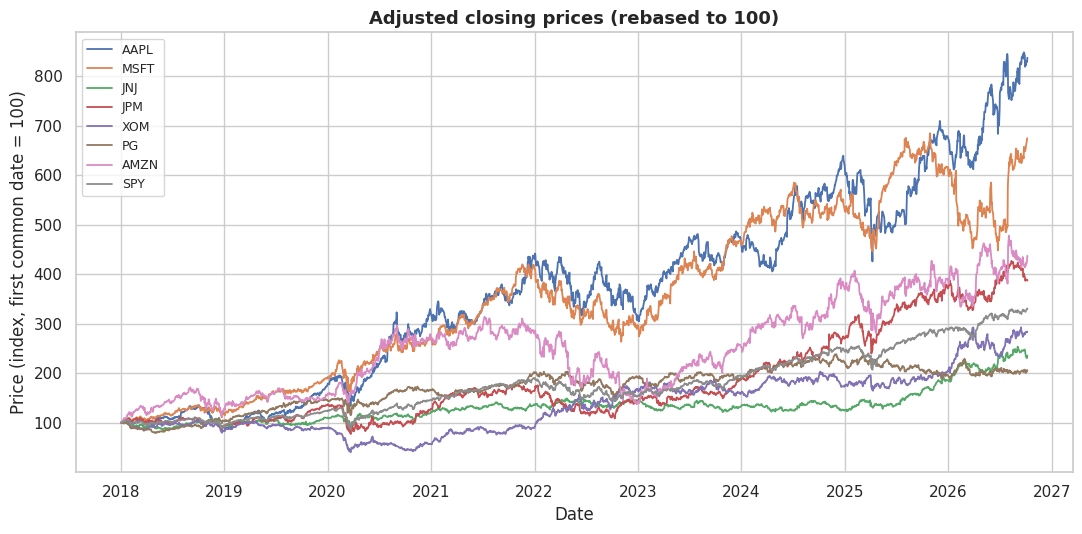

In [4]:
price_figure = plots.plot_price_series(prices, normalize=True)
price_figure

## 3. Returns

Simple returns (`P_t/P_{t-1} - 1`) drive the risk metrics; log returns
(`ln(P_t/P_{t-1})`) are the input for distributional diagnostics because they
are additive over time.

In [5]:
simple_rets = metrics.simple_returns(prices)
log_rets = metrics.log_returns(prices)
simple_rets.describe().round(5)

,AAPL,MSFT,JNJ,JPM,XOM,PG,AMZN,SPY
count,2202.00000,2202.00000,2202.00000,2202.00000,2202.00000,2202.00000,2202.00000,2202.00000
mean,0.00115,0.00103,0.00047,0.00078,0.00065,0.00041,0.00090,0.00061
std,0.01917,0.01832,0.01237,0.01796,0.01888,0.01262,0.02169,0.01196
min,-0.12865,-0.14739,-0.10038,-0.14965,-0.12225,-0.08737,-0.14049,-0.10942
25%,-0.00789,-0.00780,-0.00542,-0.00763,-0.00945,-0.00576,-0.01041,-0.00428
50%,0.00121,0.00116,0.00053,0.00095,0.00060,0.00076,0.00093,0.00083
75%,0.01092,0.01042,0.00667,0.00927,0.01071,0.00696,0.01234,0.00651
max,0.15329,0.15507,0.07998,0.18013,0.12687,0.12009,0.15321,0.10502


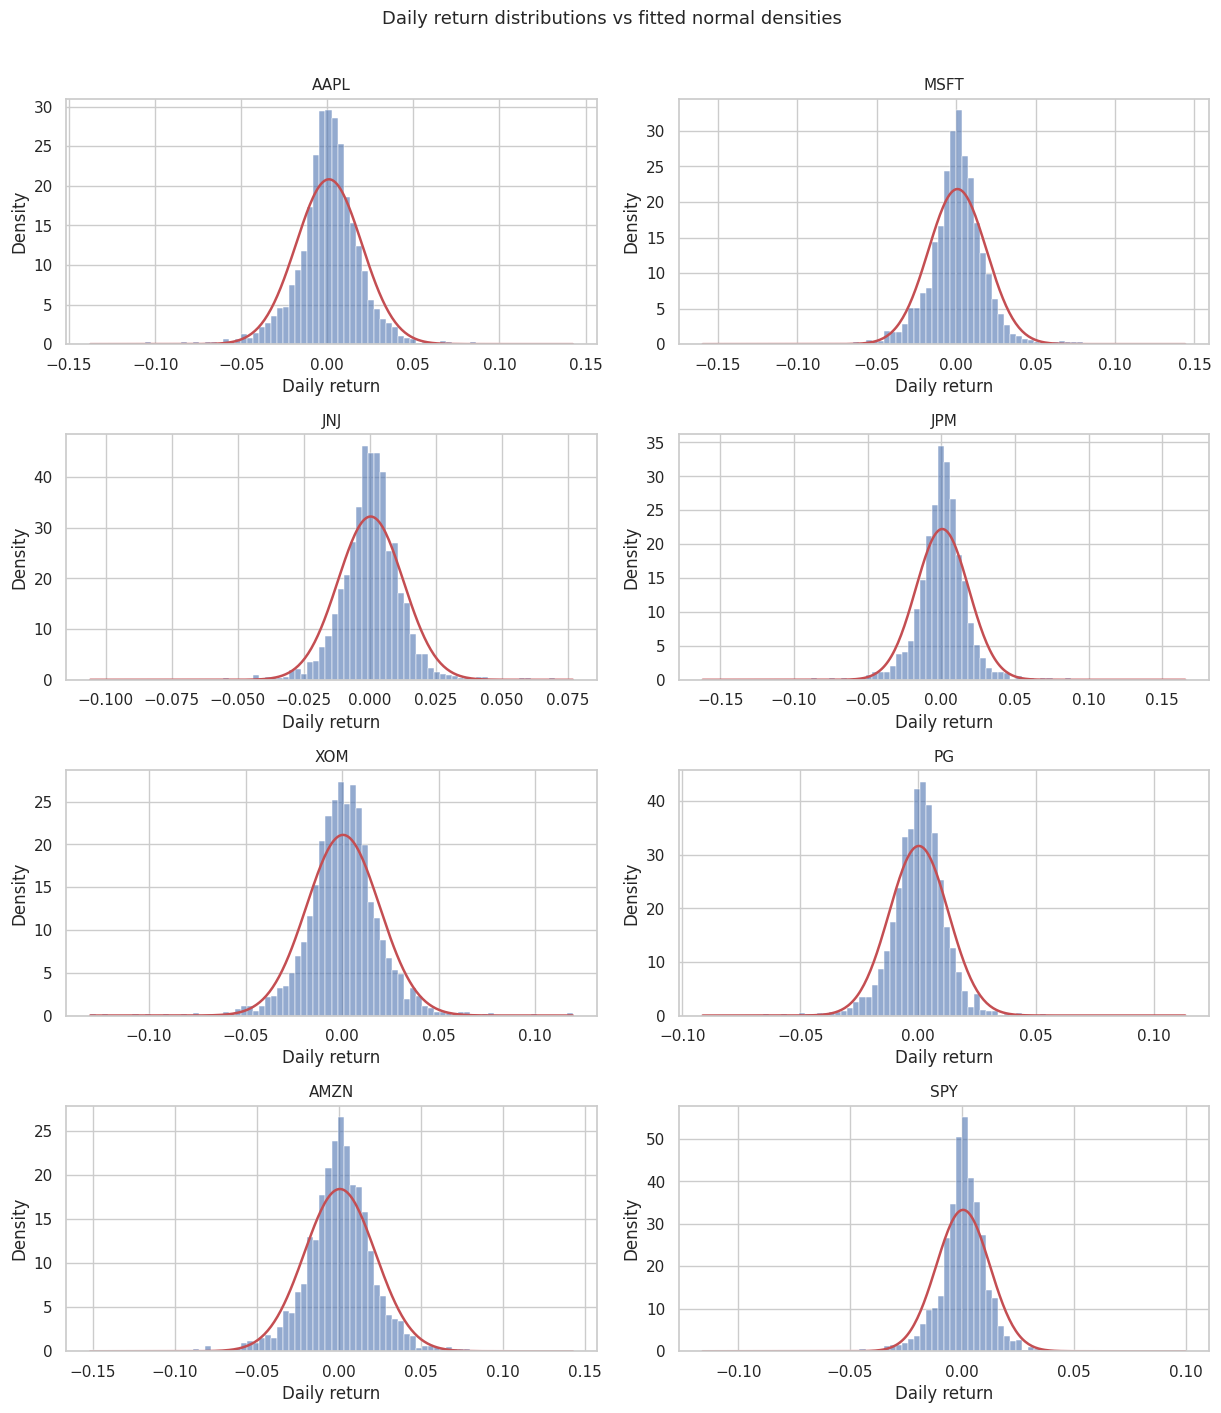

In [6]:
histograms = plots.plot_return_histogram_grid(log_rets)
histograms

Every panel overlays the Gaussian with the same sample mean and variance.
The visible peakiness and occasional extreme observations (2020 COVID crash,
2022 rate-driven bear market) are what the Jarque-Bera test formalises below.

## 4. Cumulative growth of one unit vs the SPY benchmark

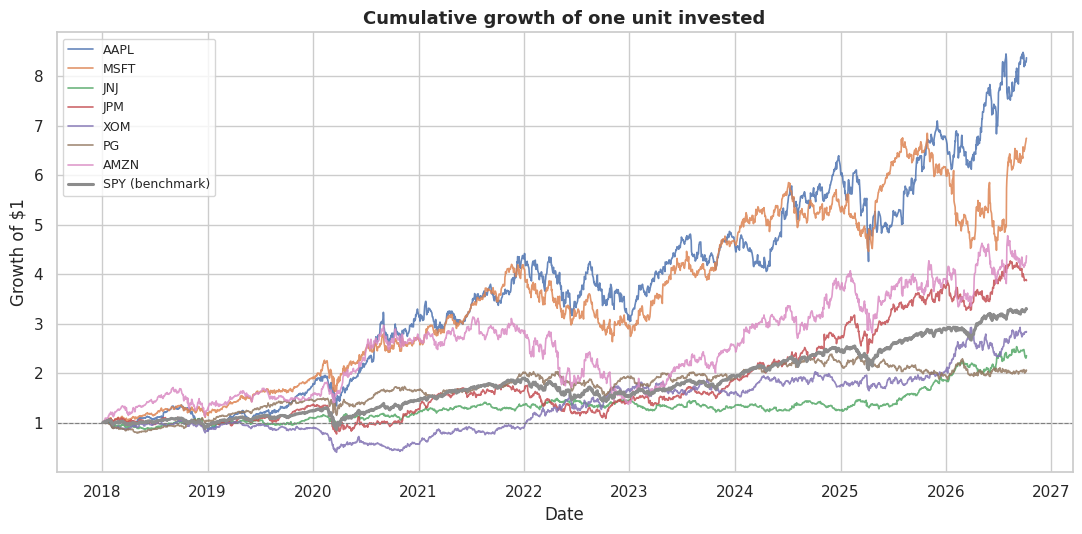

In [7]:
cumulative = plots.plot_cumulative_returns(simple_rets, config.benchmark)
cumulative

## 5. Drawdown profiles

The drawdown series measures the loss from each date's running maximum — a
direct, interpretable summary of *how bad it felt* to hold each asset.

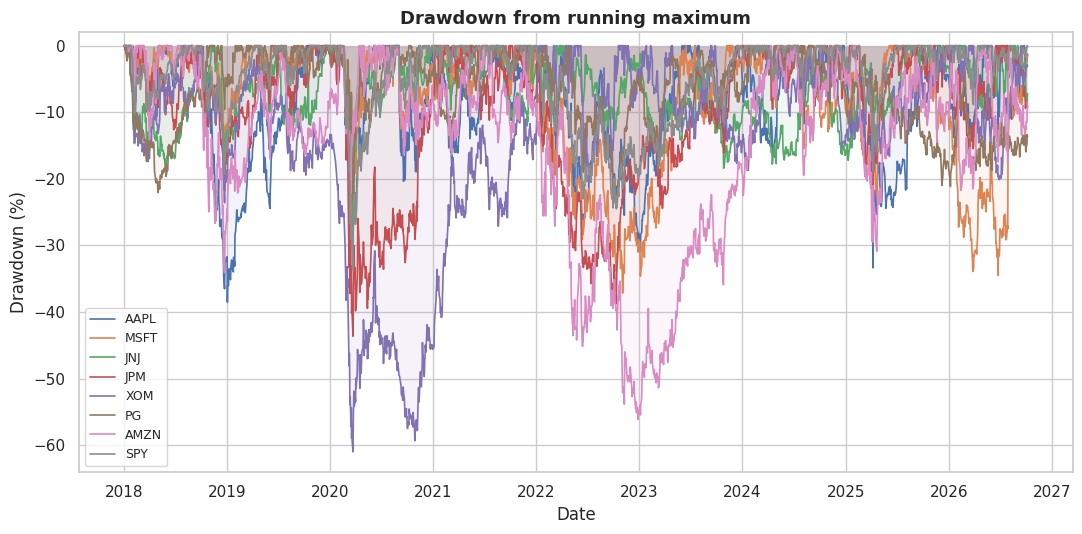

In [8]:
drawdowns = plots.plot_drawdowns(prices)
drawdowns

## 6. Rolling volatility (63 trading days ≈ one quarter)

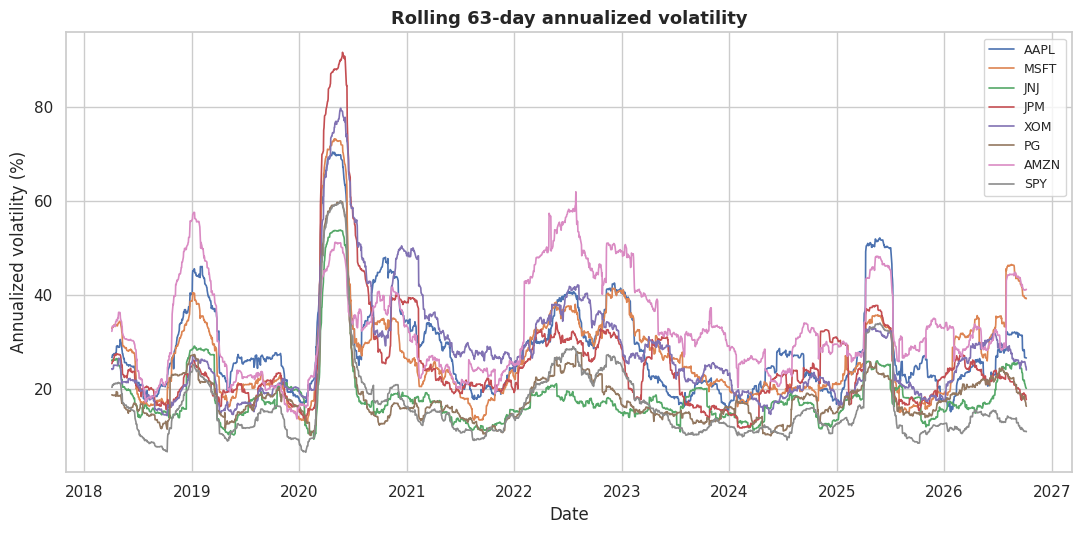

In [9]:
rolling_vol = plots.plot_rolling_volatility(simple_rets, window=63)
rolling_vol

## 7. Cross-correlation of daily returns

Correlation here is a *descriptive co-movement* statistic over the whole
sample; it is not a structural or causal claim.

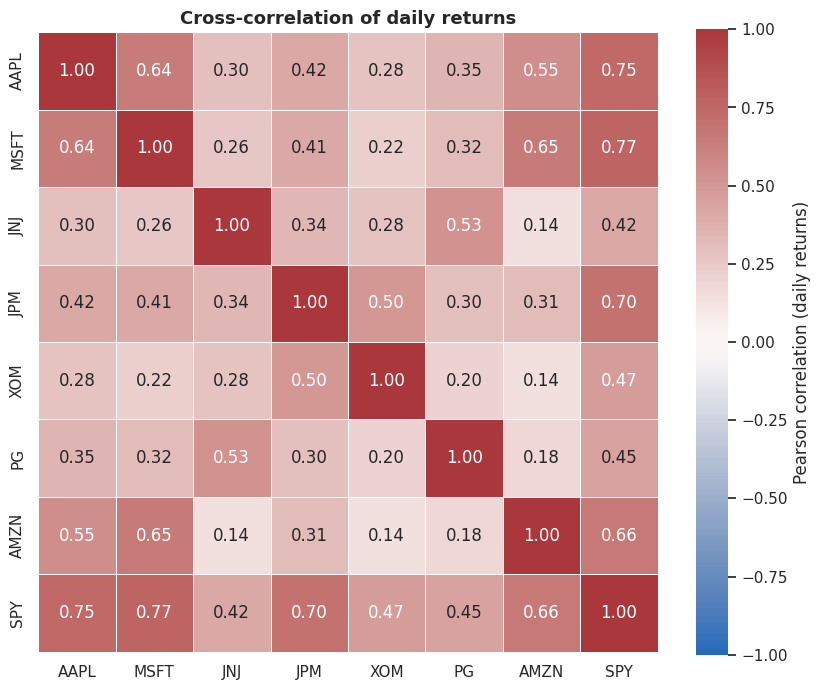

In [10]:
corr = plots.plot_correlation_heatmap(simple_rets)
corr

## 8. Statistical diagnostics

For each series: Jarque-Bera normality on log returns, Augmented Dickey-Fuller
on log price levels and on log returns, and Ljung-Box(20) on simple returns.

In [11]:
diagnostics = []
for ticker in config.all_symbols:
    ticker_log_rets = metrics.log_returns(prices[ticker])
    ticker_simple_rets = metrics.simple_returns(prices[ticker])
    jb = stats_tests.jarque_bera_test(ticker_log_rets)
    lb = stats_tests.ljung_box_test(ticker_simple_rets, lags=20)
    adf_price = stats_tests.adf_test(np.log(prices[ticker]))
    adf_return = stats_tests.adf_test(ticker_log_rets)
    diagnostics.append({
        "JB p-value": round(jb["p_value"], 4),
        "JB rejects normality": jb["reject_normality_at_5pct"],
        "skew": round(jb["skew"], 3),
        "excess kurtosis": round(jb["kurtosis"], 3),
        "ADF price p-value": round(adf_price["p_value"], 4),
        "price: unit root?": not adf_price["reject_unit_root_at_5pct"],
        "ADF return p-value": round(adf_return["p_value"], 4),
        "Ljung-Box(20) p-value": round(lb["p_values"][-1], 4),
    })
diagnostics_table = pd.DataFrame(diagnostics, index=config.all_symbols)
diagnostics_table

,JB p-value,JB rejects normality,skew,excess kurtosis,ADF price p-value,price: unit root?,ADF return p-value,Ljung-Box(20) p-value
AAPL,0.0,True,-0.120,6.097,0.7785,True,0.0,0.0000
MSFT,0.0,True,0.001,8.120,0.5553,True,0.0,0.0000
JNJ,0.0,True,-0.408,8.503,0.9636,True,0.0,0.0000
JPM,0.0,True,-0.092,12.910,0.9536,True,0.0,0.0000
XOM,0.0,True,-0.228,5.243,0.9193,True,0.0,0.0002
PG,0.0,True,-0.056,9.392,0.4173,True,0.0,0.0000
AMZN,0.0,True,0.025,4.634,0.3725,True,0.0,0.1293
SPY,0.0,True,-0.567,13.671,0.9447,True,0.0,0.0000


## 9. Descriptive metric summary

All values are computed from the validated sample; the risk-free assumption
`rf_annual` comes from `configs/default.yaml` (0.0 by default).

In [12]:
benchmark_rets = metrics.simple_returns(prices[config.benchmark])
rows = []
for ticker in config.all_symbols:
    asset_rets = metrics.simple_returns(prices[ticker])
    relative = metrics.beta_alpha(asset_rets, benchmark_rets)
    rows.append({
        "ann. return": metrics.annualized_return(prices[ticker]),
        "ann. volatility": metrics.annualized_volatility(asset_rets),
        "Sharpe": metrics.sharpe_ratio(asset_rets, config.rf_annual),
        "Sortino": metrics.sortino_ratio(asset_rets, config.rf_annual),
        "Calmar": metrics.calmar_ratio(prices[ticker]),
        "max drawdown": metrics.max_drawdown(prices[ticker]),
        "beta vs SPY": relative["beta"],
        "alpha vs SPY (ann.)": relative["alpha_annual"],
    })
metric_table = pd.DataFrame(rows, index=config.all_symbols).round(4)
metric_table.sort_values("Sharpe", ascending=False)

,ann. return,ann. volatility,Sharpe,Sortino,Calmar,max drawdown,beta vs SPY,alpha vs SPY (ann.)
AAPL,0.2752,0.3043,0.9512,1.4006,0.7146,-0.3852,1.2021,0.1034
MSFT,0.2441,0.2908,0.8964,1.3333,0.6572,-0.3715,1.1732,0.0790
SPY,0.1465,0.1898,0.8154,1.1490,0.4345,-0.3372,1.0000,-0.0000
JPM,0.1676,0.2852,0.6858,1.0057,0.3842,-0.4363,1.0524,0.0326
AMZN,0.1839,0.3443,0.6621,0.9776,0.3276,-0.5615,1.1986,0.0424
JNJ,0.1032,0.1963,0.5986,0.8532,0.3770,-0.2737,0.4325,0.0505
XOM,0.1268,0.2997,0.5483,0.7922,0.2078,-0.6101,0.7463,0.0488
PG,0.0862,0.2003,0.5131,0.7353,0.3628,-0.2377,0.4732,0.0295


## 10. What this exploration does (and does not) show

* The sample spans 2018-01-02 → 2026-10-07 (2 203 trading days, no missing
  values after validation) — including two major stress episodes.
* Daily log returns **reject normality for every series** (excess kurtosis
  roughly 4.6–13.7); Gaussian-only risk summaries would understate tail risk.
* Log price levels behave like unit-root (non-stationary) processes while log
  returns look stationary — the standard reason analysis operates on returns.
* Ranking by Sharpe in *this sample* puts AAPL and MSFT on top and PG at the
  bottom; XOM shows the deepest drawdown (≈ -61%). These are sample-descriptive
  statements, not forecasts.

**Limitations & honesty notes.** Yahoo Finance prices are delayed and
unverified; the universe contains only *currently* listed large caps
(survivorship bias); `rf_annual = 0.0` is a simplifying assumption; and no
transaction costs, taxes or microstructure effects are modelled. This notebook
is part of an educational research project and provides **no investment
advice**.